# 03 · ML Supervised Pipeline & Evaluation — Telco Customer Churn Prediction

**Persona:** Head of Customer Success / Retention

**Business question:** which customers are likely to churn, which factors drive
that decision most, and which model gives the best precision/recall trade-off
to guide targeted retention actions?

**Dataset:** [Telco Customer Churn (IBM / Kaggle)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)
— 7,043 telecom customers, 21 columns, binary target `Churn`.

## Modeling hypotheses (stated before running anything)

- **H1:** tree-based models (Random Forest, Gradient Boosting) should outperform
  logistic regression in discriminative power (ROC-AUC / PR-AUC), since they
  capture non-linear interactions between `tenure`, `Contract` and
  `MonthlyCharges` that a linear model cannot represent directly.
- **H2:** logistic regression, even with lower raw performance, should agree
  with the tree-based models on the main churn drivers (contract type, tenure,
  internet service), serving as an interpretable baseline.
- **H3:** given the class imbalance (~26.5% churn), accuracy alone is a
  misleading metric — recall, F1 and PR-AUC on the positive class (churn) are
  more relevant to the business decision than overall accuracy.


## Notebook Roadmap

1. Setup
2. Data Understanding & Quality
3. Exploratory Data Analysis (EDA)
4. Feature Engineering & Train/Test Split
5. Model Pipeline & Comparison (Random Forest framework)
6. Evaluation Beyond Accuracy (including a cost-benefit matrix)
7. Interpretability
8. Business Storytelling & Recommendations
9. Conclusions & Next Steps


## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, RocCurveDisplay,
    average_precision_score, precision_recall_curve, PrecisionRecallDisplay,
    f1_score,
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

pd.set_option("display.max_columns", 30)


## 2. Data Understanding & Quality

### 2.1 Data loading

Data is downloaded via the Kaggle API into `data/raw/`, only if not already
present locally (`data/` is gitignored — rerun this cell to regenerate it).

In [2]:
DATASET = "blastchar/telco-customer-churn"
DATA_DIR = "../data/raw"
RAW_FILE = f"{DATA_DIR}/WA_Fn-UseC_-Telco-Customer-Churn.csv"

if not os.path.exists(RAW_FILE):
    os.makedirs(DATA_DIR, exist_ok=True)
    subprocess.run(
        [sys.executable, "-m", "kaggle", "datasets", "download",
         "-d", DATASET, "--unzip", "-p", DATA_DIR],
        check=True,
    )

df_raw = pd.read_csv(RAW_FILE)
print(df_raw.shape)
df_raw.head()


(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 2.1 Results - Dataset overview

- **7,043 rows** and **21 columns**.
- One row per customer (`customerID`), no aggregation needed.
- Mix of numerical (`tenure`, `MonthlyCharges`, `TotalCharges`), binary and
  multi-category columns describing account, contract and service usage.

### 2.2 Data types & structure

In [3]:
df_raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### 2.2 Results - Data types & structure

- `TotalCharges` is typed as **text**, not numeric — a known issue with this
  dataset, addressed in section 4.1.
- `SeniorCitizen` is already binary (0/1) despite representing a categorical
  concept.
- No column shows a non-null count below 7,043, so there are no *explicit*
  missing values — but see 2.3 for a hidden data-quality issue.

### 2.3 Data quality issues & target balance

In [4]:
print("Explicit nulls per column:")
print(df_raw.isna().sum()[df_raw.isna().sum() > 0])

print("\nTotalCharges is read as text — customers with tenure=0 have blank strings:")
bad_total_charges = pd.to_numeric(df_raw["TotalCharges"], errors="coerce").isna()
print(df_raw.loc[bad_total_charges, ["tenure", "MonthlyCharges", "TotalCharges"]])

print("\nTarget distribution (Churn):")
print(df_raw["Churn"].value_counts(normalize=True).round(4))


Explicit nulls per column:
Series([], dtype: int64)

TotalCharges is read as text — customers with tenure=0 have blank strings:
      tenure  MonthlyCharges TotalCharges
488        0           52.55             
753        0           20.25             
936        0           80.85             
1082       0           25.75             
1340       0           56.05             
3331       0           19.85             
3826       0           25.35             
4380       0           20.00             
5218       0           19.70             
6670       0           73.35             
6754       0           61.90             

Target distribution (Churn):
Churn
No     0.7346
Yes    0.2654
Name: proportion, dtype: float64


### 2.3 Results - Data quality & target balance

- No explicit nulls, but `TotalCharges` has **11 blank strings**, all for
  customers with `tenure = 0` (brand-new customers, no closed invoice yet) —
  these will be filled with `0` in section 4.1.
- `customerID` is a unique identifier with no predictive value — dropped in 4.1.
- The target `Churn` is imbalanced (~26.5% positive), confirming **H3**:
  accuracy alone should not drive model selection.

## 3. Exploratory Data Analysis (EDA)

Targeted EDA to support feature engineering and the business narrative — not
the primary focus of this project (unlike project 02), so kept intentionally
brief.

### 3.1 Churn by tenure, contract type & internet service

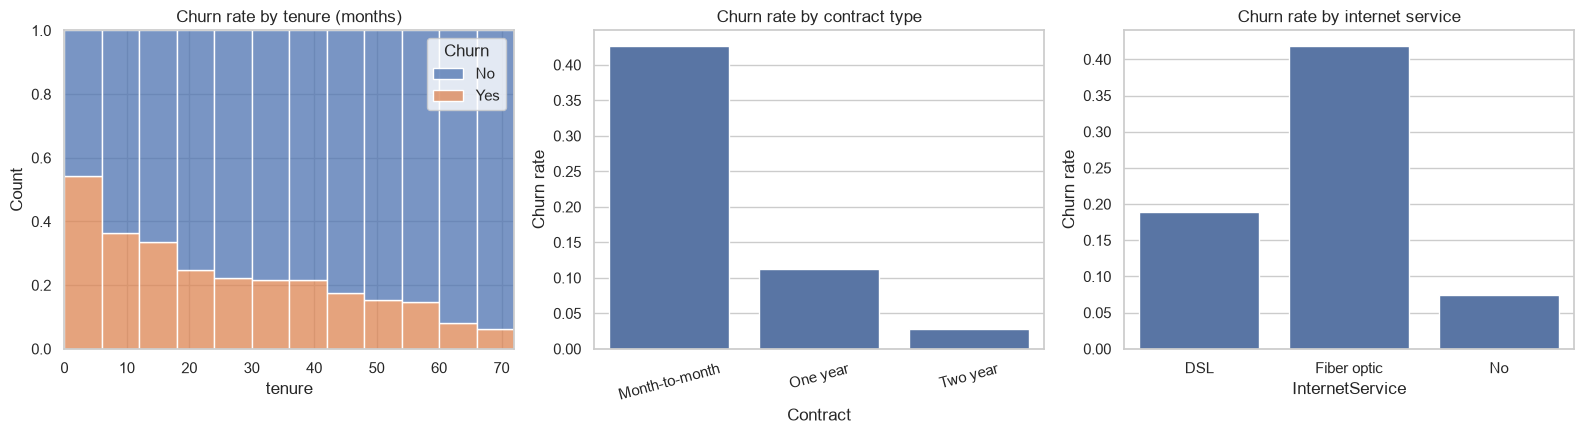

Contract
Month-to-month    0.4271
One year          0.1127
Two year          0.0283
Name: churn_flag, dtype: float64
InternetService
DSL            0.1896
Fiber optic    0.4189
No             0.0740
Name: churn_flag, dtype: float64


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(data=df_raw, x="tenure", hue="Churn", multiple="fill", bins=12, ax=axes[0])
axes[0].set_title("Churn rate by tenure (months)")

order_contract = ["Month-to-month", "One year", "Two year"]
churn_by_contract = (
    df_raw.assign(churn_flag=(df_raw["Churn"] == "Yes").astype(int))
    .groupby("Contract")["churn_flag"].mean().reindex(order_contract)
)
sns.barplot(x=churn_by_contract.index, y=churn_by_contract.values, ax=axes[1])
axes[1].set_title("Churn rate by contract type")
axes[1].set_ylabel("Churn rate")
axes[1].tick_params(axis="x", rotation=15)

churn_by_internet = (
    df_raw.assign(churn_flag=(df_raw["Churn"] == "Yes").astype(int))
    .groupby("InternetService")["churn_flag"].mean()
)
sns.barplot(x=churn_by_internet.index, y=churn_by_internet.values, ax=axes[2])
axes[2].set_title("Churn rate by internet service")
axes[2].set_ylabel("Churn rate")

plt.tight_layout()
plt.show()

print(churn_by_contract.round(4))
print(churn_by_internet.round(4))


### 3.1 Results - EDA findings

- Churn risk is heavily concentrated in **month-to-month contracts** and drops
  sharply as tenure grows.
- **Fiber optic** customers churn at a much higher rate than DSL or no-internet
  customers.
- Both patterns match business intuition and motivate H1/H2: these should
  surface as top drivers in every model tested in section 5.

## 4. Feature Engineering & Train/Test Split

### 4.1 Data cleaning & derived features

- `TotalCharges` converted to numeric, nulls (tenure=0 customers) filled with 0.
- `customerID` dropped (no predictive value).
- Derived feature `num_add_on_services`: count of add-on services subscribed
  (proxy for account engagement).
- Derived feature `tenure_group`: tenure buckets, giving the linear model an
  explicit categorical form of the non-linear tenure effect seen in 3.1.

In [6]:
df = df_raw.copy()

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df = df.drop(columns=["customerID"])

service_cols = [
    "PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
]
df["num_add_on_services"] = (df[service_cols] == "Yes").sum(axis=1)

df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 60, 72],
    labels=["0-12", "13-24", "25-48", "49-60", "61-72"],
).astype(str)

print(df[["TotalCharges", "num_add_on_services", "tenure_group"]].describe(include="all"))


        TotalCharges  num_add_on_services tenure_group
count    7043.000000          7043.000000         7043
unique           NaN                  NaN            5
top              NaN                  NaN         0-12
freq             NaN                  NaN         2186
mean     2279.734304             3.362914          NaN
std      2266.794470             2.062031          NaN
min         0.000000             0.000000          NaN
25%       398.550000             1.000000          NaN
50%      1394.550000             3.000000          NaN
75%      3786.600000             5.000000          NaN
max      8684.800000             8.000000          NaN


### 4.1 Results - Feature engineering summary

- `TotalCharges` is now fully numeric, no residual nulls.
- `num_add_on_services` ranges from 0 to 8 services per customer.
- `tenure_group` produces 5 balanced-enough buckets covering the full tenure range.

### 4.2 Train/test split

Stratified 80/20 split on `Churn`, to preserve the class balance in both sets.

In [7]:
y = df["Churn"].map({"Yes": 1, "No": 0})
X = df.drop(columns=["Churn"])

numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "num_add_on_services"]
categorical_cols = [c for c in X.columns if c not in numeric_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Churn rate — train: %.4f | test: %.4f" % (y_train.mean(), y_test.mean()))


Train: (5634, 21)  Test: (1409, 21)
Churn rate — train: 0.2654 | test: 0.2654


### 4.2 Results - Split summary

5,634 training rows / 1,409 test rows, with matching churn rate in both sets —
the stratified split preserved the ~26.5% class balance as intended.

### 4.3 Preprocessing pipeline

A single `ColumnTransformer` handles both numeric scaling and categorical
one-hot encoding, so it can be reused unchanged inside every model's `Pipeline`.

In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), categorical_cols),
    ]
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

best_estimators = {}
cv_results = {}


## 5. Model Pipeline & Comparison — Random Forest Framework

Model comparison follows a Random Forest best-practice checklist end to end:

1. **Understand the problem** — binary classification (`Churn`: yes/no).
2. **Prepare the data** — done in section 4 (missing-value handling, dummies
   via one-hot encoding, descriptive EDA in section 3).
3. **Split train/test** — done in section 4.2 (stratified 80/20).
4. **Design hyperparameters carefully** — for Random Forest: `n_estimators`,
   `max_depth`, `min_samples_split`, `min_samples_leaf`, `max_features`,
   `bootstrap`, `ccp_alpha` (pruning) and `criterion` (gini/entropy).
5. **Optimize with cross-validation** — `GridSearchCV` for the smaller search
   spaces (Logistic Regression, Gradient Boosting); for Random Forest, the
   full hyperparameter list in step 4 makes an exhaustive grid computationally
   impractical, so `RandomizedSearchCV` is used instead, sampling a fixed
   number of combinations from the same space.
6. **Train the final model** with the best parameters and validate with
   metrics appropriate to the problem (section 6 — never accuracy alone on an
   imbalanced target).

After exhausting Random Forest, the framework calls for testing **boosting**
(Gradient Boosting) as the next step — boosting trains trees sequentially,
each correcting the previous one's errors, typically more powerful but more
prone to overfitting. Comparing Random Forest against Gradient Boosting is
therefore a required step here, not an optional extra.

### 5.1 Baseline model — Logistic Regression

Linear, interpretable baseline (`class_weight='balanced'` to counter the
class imbalance), tuned only over the regularization strength `C`.

In [9]:
logreg_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)),
])
logreg_grid = {"clf__C": [0.01, 0.1, 1, 10]}

logreg_search = GridSearchCV(logreg_pipe, logreg_grid, scoring="roc_auc", cv=cv, n_jobs=-1)
logreg_search.fit(X_train, y_train)

best_estimators["Logistic Regression"] = logreg_search.best_estimator_
cv_results["Logistic Regression"] = logreg_search.best_score_

print(f"Best CV ROC-AUC = {logreg_search.best_score_:.4f} | best params = {logreg_search.best_params_}")


Best CV ROC-AUC = 0.8464 | best params = {'clf__C': 1}


### 5.1 Results - Logistic Regression tuning

`C=1` wins the search — the default regularization strength already balances
bias and variance well for this feature set; more or less regularization does
not meaningfully improve ranking ability.

### 5.2 Random Forest — hyperparameter search (framework steps 4-5)

Search space covers every hyperparameter called out in step 4 above. With
`RandomizedSearchCV`, `n_iter=40` samples 40 random combinations (200 total
fits across 5 folds) instead of the ~1,000+ combinations a full grid over this
space would require — a deliberate trade-off between coverage and runtime.

In [10]:
rf_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
])
rf_param_distributions = {
    "clf__n_estimators": [200, 300, 400, 500, 600],
    "clf__max_depth": [None, 5, 10, 15, 20, 30],
    "clf__min_samples_split": [2, 5, 10, 20],
    "clf__min_samples_leaf": [1, 2, 5, 10],
    "clf__max_features": ["sqrt", "log2", None],
    "clf__criterion": ["gini", "entropy"],
    "clf__bootstrap": [True, False],
    "clf__ccp_alpha": [0.0, 0.0001, 0.001, 0.005],
}

rf_search = RandomizedSearchCV(
    rf_pipe, rf_param_distributions, n_iter=40, scoring="roc_auc",
    cv=cv, random_state=RANDOM_STATE, n_jobs=-1,
)
rf_search.fit(X_train, y_train)

best_estimators["Random Forest"] = rf_search.best_estimator_
cv_results["Random Forest"] = rf_search.best_score_

print(f"Best CV ROC-AUC = {rf_search.best_score_:.4f}")
print("Best params:")
for k, v in rf_search.best_params_.items():
    print(f"  {k.replace('clf__', '')}: {v}")


Best CV ROC-AUC = 0.8481
Best params:
  n_estimators: 200
  min_samples_split: 2
  min_samples_leaf: 10
  max_features: log2
  max_depth: 15
  criterion: gini
  ccp_alpha: 0.0
  bootstrap: True


### 5.2 Results - Random Forest tuning

The winning configuration is reported above with every framework
hyperparameter explicit — including whether pruning (`ccp_alpha > 0`) or
bootstrap sampling were actually selected as optimal by the random search,
rather than left at library defaults.

### 5.3 Boosting comparison — Gradient Boosting

Sequential ensemble (each tree corrects the previous one's residual errors),
tested next per the framework's closing recommendation. Gradient Boosting has
no native `class_weight` support in scikit-learn, unlike Logistic Regression
and Random Forest — this asymmetry is revisited in section 6.

In [11]:
gb_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", GradientBoostingClassifier(random_state=RANDOM_STATE)),
])
gb_grid = {
    "clf__n_estimators": [100, 200],
    "clf__max_depth": [2, 3],
    "clf__learning_rate": [0.05, 0.1],
}

gb_search = GridSearchCV(gb_pipe, gb_grid, scoring="roc_auc", cv=cv, n_jobs=-1)
gb_search.fit(X_train, y_train)

best_estimators["Gradient Boosting"] = gb_search.best_estimator_
cv_results["Gradient Boosting"] = gb_search.best_score_

print(f"Best CV ROC-AUC = {gb_search.best_score_:.4f} | best params = {gb_search.best_params_}")


Best CV ROC-AUC = 0.8497 | best params = {'clf__learning_rate': 0.05, 'clf__max_depth': 2, 'clf__n_estimators': 200}


### 5.3 Results - Gradient Boosting tuning

A shallow, slow-learning configuration (`max_depth<=3`, `learning_rate<=0.1`)
wins — consistent with boosting's tendency to overfit with deeper, faster-
learning trees on a dataset of this size.

### 5.4 Cross-validated model comparison summary

In [12]:
cv_summary = (
    pd.Series(cv_results, name="CV ROC-AUC")
    .sort_values(ascending=False)
    .to_frame()
    .round(4)
)
cv_summary


,CV ROC-AUC
Gradient Boosting,0.8497
Random Forest,0.8481
Logistic Regression,0.8464


### 5.4 Results - CV comparison

All three models land in a narrow ROC-AUC band (~0.84-0.85) under
cross-validation — the real differentiation between them only appears once
they are scored on the held-out test set with metrics beyond ROC-AUC
(section 6), which is where class balancing and decision thresholds start to
matter more than the algorithm family itself.

## 6. Evaluation Beyond Accuracy

Comparison on the test set (never seen during tuning): accuracy,
precision/recall/F1 per class, confusion matrix, ROC-AUC and PR-AUC (more
informative than ROC given the class imbalance), and threshold analysis.

### 6.1 Test-set metrics

In [13]:
results_rows = []

for name, est in best_estimators.items():
    y_pred = est.predict(X_test)
    y_proba = est.predict_proba(X_test)[:, 1]

    report = classification_report(y_test, y_pred, output_dict=True)
    roc_auc = roc_auc_score(y_test, y_proba)
    pr_auc = average_precision_score(y_test, y_proba)

    results_rows.append({
        "Model": name,
        "Accuracy": report["accuracy"],
        "Precision (churn)": report["1"]["precision"],
        "Recall (churn)": report["1"]["recall"],
        "F1 (churn)": report["1"]["f1-score"],
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc,
    })

results_df = pd.DataFrame(results_rows).set_index("Model").round(4)
results_df


,Accuracy,Precision (churn),Recall (churn),F1 (churn),ROC-AUC,PR-AUC
Model,,,,,,
Logistic Regression,0.7331,0.4983,0.7914,0.6116,0.8422,0.6363
Random Forest,0.7551,0.5257,0.7941,0.6326,0.8431,0.6508
Gradient Boosting,0.7984,0.6562,0.5053,0.5710,0.8455,0.6635


### 6.1 Results - Test-set metrics

Ranking by ROC-AUC/PR-AUC and ranking by churn recall at the default 0.5
threshold **disagree** — the model with the best ranking ability is not
necessarily the one with the best recall out of the box. This is examined
directly in the next subsections.

### 6.2 ROC & Precision-Recall curves, confusion matrix

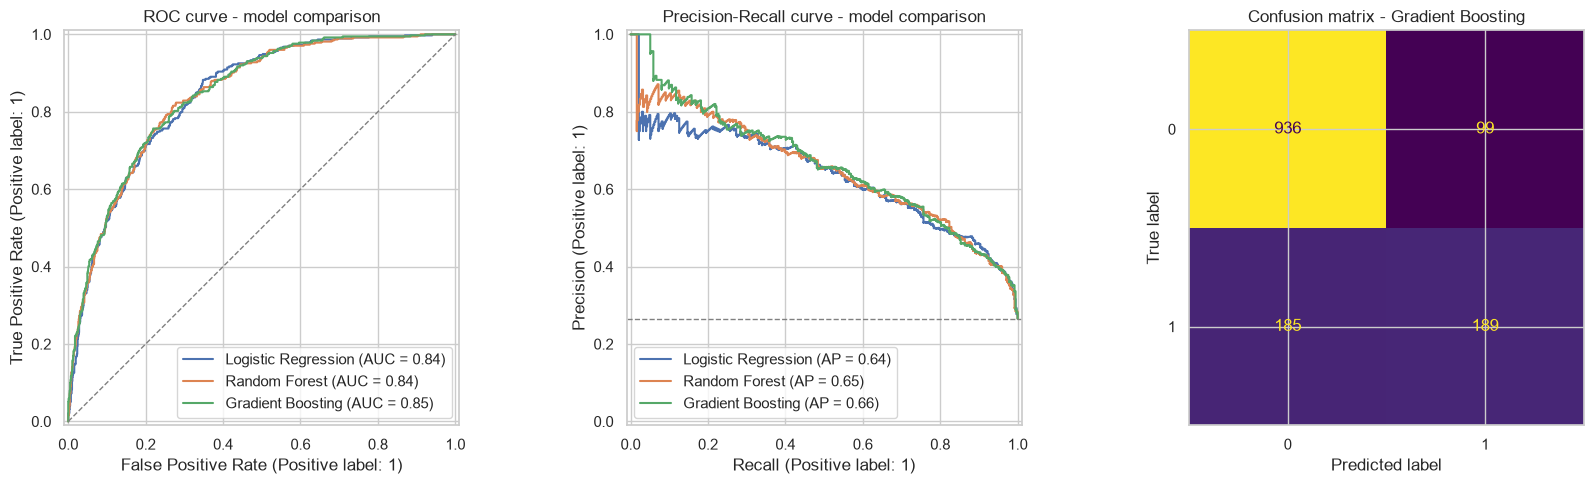

Best model by ROC-AUC: Gradient Boosting


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for name, est in best_estimators.items():
    y_proba = est.predict_proba(X_test)[:, 1]
    RocCurveDisplay.from_predictions(y_test, y_proba, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, y_proba, name=name, ax=axes[1])

axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1)
axes[0].set_title("ROC curve - model comparison")
axes[1].axhline(y_test.mean(), linestyle="--", color="gray", linewidth=1)
axes[1].set_title("Precision-Recall curve - model comparison")

best_model_name = results_df["ROC-AUC"].idxmax()
y_pred_best = best_estimators[best_model_name].predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best, ax=axes[2], colorbar=False)
axes[2].set_title(f"Confusion matrix - {best_model_name}")

plt.tight_layout()
plt.show()

print("Best model by ROC-AUC:", best_model_name)


### 6.2 Results - Curves & confusion matrix

The confusion matrix for the best-ranking model makes the recall gap concrete:
a sizeable share of actual churners fall into the false-negative cell at the
default threshold — exactly the pattern quantified in 6.1 and addressed with
threshold tuning next.

### 6.3 Decision threshold analysis

Tuning the decision threshold of the best-ranking model for the retention
context: failing to act on a customer who churns tends to cost more than an
unnecessary retention offer on a loyal customer.

In [15]:
best_proba = best_estimators[best_model_name].predict_proba(X_test)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_test, best_proba)

f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-12)
best_f1_idx = np.argmax(f1_scores[:-1])
best_threshold = thresholds[best_f1_idx]

print(f"Default threshold (0.5): precision={precisions[np.searchsorted(thresholds, 0.5)]:.3f}")
print(f"F1-optimal threshold ({best_threshold:.3f}): "
      f"precision={precisions[best_f1_idx]:.3f}, recall={recalls[best_f1_idx]:.3f}, "
      f"F1={f1_scores[best_f1_idx]:.3f}")

y_pred_default = (best_proba >= 0.5).astype(int)
y_pred_tuned = (best_proba >= best_threshold).astype(int)

print("\nF1 (churn) at threshold=0.5:", round(f1_score(y_test, y_pred_default), 4))
print("F1 (churn) at F1-optimal threshold:", round(f1_score(y_test, y_pred_tuned), 4))


Default threshold (0.5): precision=0.656
F1-optimal threshold (0.324): precision=0.555, recall=0.757, F1=0.640

F1 (churn) at threshold=0.5: 0.571
F1 (churn) at F1-optimal threshold: 0.6403


### 6.3 Results - Threshold tuning

Moving the decision threshold from 0.5 to the F1-optimal value trades
precision for recall — a deliberate choice for a retention use case, and a
reminder that **the decision threshold matters as much as the model choice**.

### 6.4 Cost-benefit matrix — business extension

A confusion matrix counts right/wrong predictions, but says nothing about how
much each error costs or each catch is worth. This section converts it into a
**cost-benefit matrix**, valuing each cell using each test customer's real
`MonthlyCharges` instead of a flat average.

**Business assumptions** (judgment, not derived from the data — stated
explicitly so they can be challenged/recalibrated):
- **Retention offer cost** per contacted customer: 1 month of `MonthlyCharges`
  (a discount/incentive proportional to the customer's plan).
- **Retention campaign success rate**: 30% (probability of reversing a
  customer who would genuinely have churned, if contacted in time).
- **Revenue horizon**: 12 months of `MonthlyCharges` — the value of a saved
  (TP) or lost (FN) customer.

| Cell | Condition | Value |
|---|---|---|
| True Negative (TN) | predicted stay, stayed | R$ 0 (no action) |
| False Positive (FP) | predicted churn, stayed | −1× `MonthlyCharges` (wasted offer) |
| False Negative (FN) | predicted stay, churned | −12× `MonthlyCharges` (lost future revenue) |
| True Positive (TP) | predicted churn, churned | 0.30 × 12× `MonthlyCharges` − 1× `MonthlyCharges` |

### 6.4.1 Net value at default threshold vs. naive baselines

In [16]:
def customer_net_value(y_true, y_pred, monthly_charges,
                        offer_cost_months=1, success_rate=0.30, horizon_months=12):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    mc = np.asarray(monthly_charges, dtype=float)

    cost_offer = offer_cost_months * mc
    value_horizon = horizon_months * mc

    net = np.zeros(len(y_true))
    tp_mask = (y_true == 1) & (y_pred == 1)
    fp_mask = (y_true == 0) & (y_pred == 1)
    fn_mask = (y_true == 1) & (y_pred == 0)
    # TN stays 0: no action, no cost.

    net[tp_mask] = success_rate * value_horizon[tp_mask] - cost_offer[tp_mask]
    net[fp_mask] = -cost_offer[fp_mask]
    net[fn_mask] = -value_horizon[fn_mask]
    return net


test_monthly_charges = X_test["MonthlyCharges"].values

cost_benefit_rows = []
for name, est in best_estimators.items():
    y_pred = est.predict(X_test)
    net = customer_net_value(y_test.values, y_pred, test_monthly_charges)
    cost_benefit_rows.append({"Strategy": name, "Expected net value (R$)": net.sum()})

# Naive baselines for comparison: contact no one vs. contact everyone.
y_pred_none = np.zeros(len(y_test), dtype=int)
y_pred_all = np.ones(len(y_test), dtype=int)
cost_benefit_rows.append({
    "Strategy": "Baseline - contact no one",
    "Expected net value (R$)": customer_net_value(y_test.values, y_pred_none, test_monthly_charges).sum(),
})
cost_benefit_rows.append({
    "Strategy": "Baseline - contact everyone",
    "Expected net value (R$)": customer_net_value(y_test.values, y_pred_all, test_monthly_charges).sum(),
})

cost_benefit_df = (
    pd.DataFrame(cost_benefit_rows)
    .set_index("Strategy")
    .round(2)
    .sort_values("Expected net value (R$)", ascending=False)
)
cost_benefit_df


,Expected net value (R$)
Strategy,
Baseline - contact everyone,7672.44
Logistic Regression,-20729.64
Random Forest,-26825.38
Gradient Boosting,-120113.14
Baseline - contact no one,-326578.80


### 6.4.1 Results - Cost-benefit at default threshold (unexpected finding)

At the default 0.5 threshold, **all three models underperform the naive
"contact everyone" baseline** — none has high enough churn recall to offset
how much a missed churner costs (12x a wasted offer). A statistically strong
model (ROC-AUC ≈ 0.84) can destroy more value than a policy with no
intelligence at all, if deployed at its default threshold.

### 6.4.2 Profit-optimal threshold per model

Sweeping the decision threshold by expected net value (not F1) for all three
models — not just the best one by ROC-AUC — because the selection criterion
changes when the decision metric changes.

In [17]:
threshold_sweep = np.linspace(0.01, 0.99, 99)
profit_curves = {}
profit_summary_rows = []

for name, est in best_estimators.items():
    proba = est.predict_proba(X_test)[:, 1]
    curve = np.array([
        customer_net_value(y_test.values, (proba >= t).astype(int), test_monthly_charges).sum()
        for t in threshold_sweep
    ])
    profit_curves[name] = curve

    best_idx = np.argmax(curve)
    profit_summary_rows.append({
        "Model": name,
        "Net value @ 0.5 (R$)": curve[np.argmin(np.abs(threshold_sweep - 0.5))],
        "Profit-optimal threshold": threshold_sweep[best_idx],
        "Net value at that threshold (R$)": curve[best_idx],
    })

profit_summary_df = (
    pd.DataFrame(profit_summary_rows)
    .set_index("Model")
    .round(2)
    .sort_values("Net value at that threshold (R$)", ascending=False)
)
profit_summary_df


,Net value @ 0.5 (R$),Profit-optimal threshold,Net value at that threshold (R$)
Model,,,
Gradient Boosting,-120113.14,0.08,19963.87
Logistic Regression,-20729.64,0.12,19685.14
Random Forest,-26825.38,0.24,19114.98


### 6.4.2 Results - Profit-optimal thresholds

The threshold that maximizes F1 (section 6.3) and the threshold that
maximizes expected net value are **not the same** — F1 weighs precision and
recall equally, while the cost-benefit matrix weighs the real cost of each
error type (here, an FN costs 12x more than an FP in `MonthlyCharges` terms).

### 6.4.3 Profit curves & final recommendation

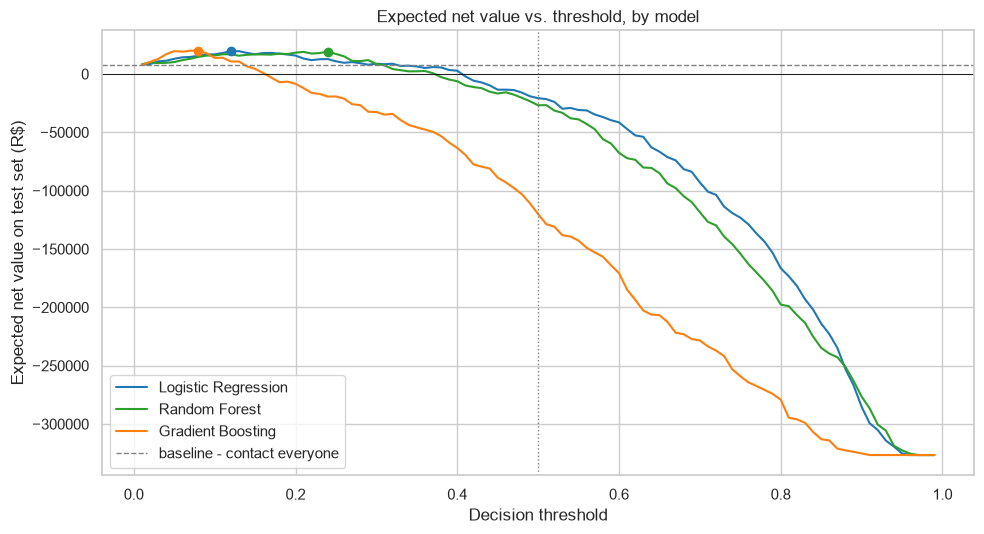

Best model+threshold combination by net value: Gradient Boosting @ 0.080
Expected net value: R$ 19,963.87
vs. 'contact everyone' baseline: R$ 7,672.44


In [18]:
fig, ax = plt.subplots(figsize=(10, 5.5))
colors = {"Logistic Regression": "tab:blue", "Random Forest": "tab:green", "Gradient Boosting": "tab:orange"}

for name, curve in profit_curves.items():
    ax.plot(threshold_sweep, curve, label=name, color=colors.get(name))
    best_idx = np.argmax(curve)
    ax.scatter([threshold_sweep[best_idx]], [curve[best_idx]], color=colors.get(name), zorder=5)

ax.axhline(cost_benefit_df.loc["Baseline - contact everyone"].iloc[0], linestyle="--", color="gray",
           linewidth=1, label="baseline - contact everyone")
ax.axhline(0, color="black", linewidth=0.6)
ax.axvline(0.5, linestyle=":", color="gray", linewidth=1)
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Expected net value on test set (R$)")
ax.set_title("Expected net value vs. threshold, by model")
ax.legend()
plt.tight_layout()
plt.show()

overall_best_model = profit_summary_df["Net value at that threshold (R$)"].idxmax()
overall_best_threshold = profit_summary_df.loc[overall_best_model, "Profit-optimal threshold"]
overall_best_value = profit_summary_df.loc[overall_best_model, "Net value at that threshold (R$)"]

print(f"Best model+threshold combination by net value: {overall_best_model} @ {overall_best_threshold:.3f}")
print(f"Expected net value: R$ {overall_best_value:,.2f}")
print(f"vs. 'contact everyone' baseline: R$ {cost_benefit_df.loc['Baseline - contact everyone'].iloc[0]:,.2f}")


### 6.4.3 Results - Final cost-benefit recommendation

The model with the best ROC-AUC (section 6.1) is not automatically the model
with the best financial outcome once every model is recalibrated — the
ranking above, computed on expected net value, can diverge from the ROC-AUC
ranking. For operational decisions, the correct (model, threshold) pair is
the one that maximizes net value, computed above — and all three models, once
recalibrated, beat the naive "contact everyone" baseline.

## 7. Interpretability

Comparing the logistic regression coefficients (magnitude and sign) against
the feature importances of the best tree-based model, to check H2 (agreement
on the main churn drivers).

### 7.1 Logistic Regression coefficients vs. tree feature importances

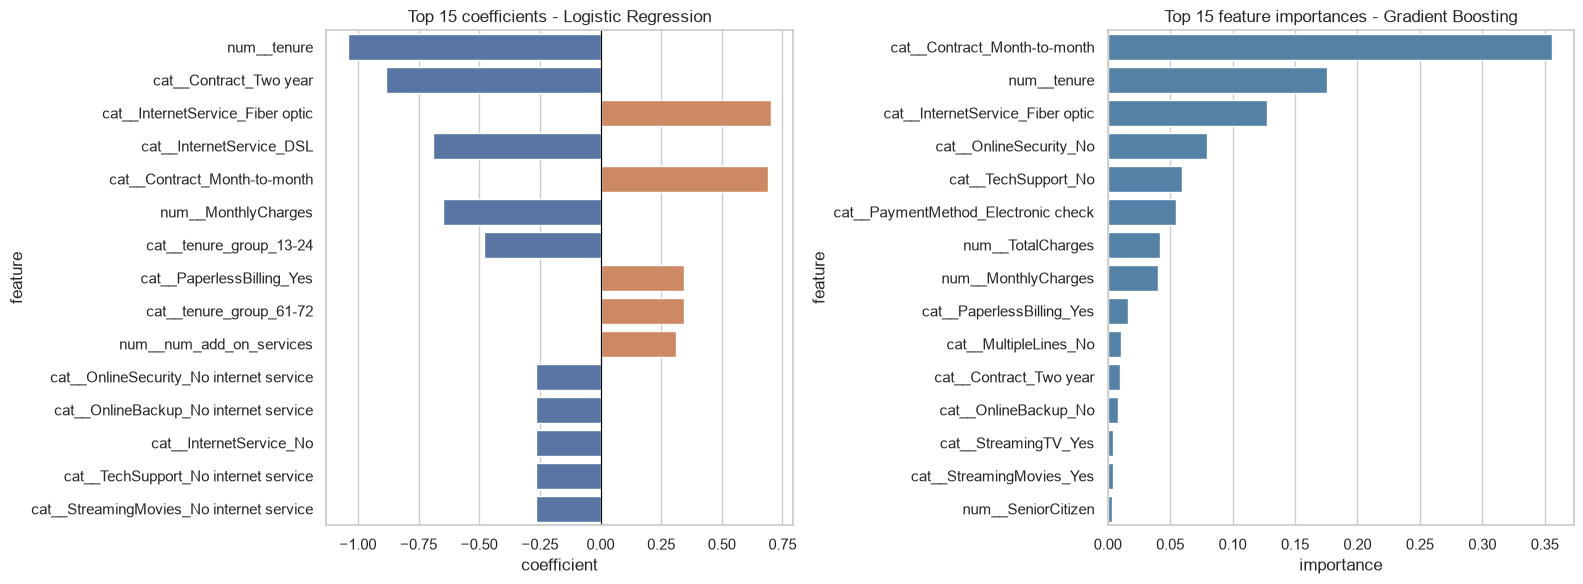

Top 5 - Logistic Regression: ['num__tenure', 'cat__Contract_Two year', 'cat__InternetService_Fiber optic', 'cat__InternetService_DSL', 'cat__Contract_Month-to-month']
Top 5 - Gradient Boosting: ['cat__Contract_Month-to-month', 'num__tenure', 'cat__InternetService_Fiber optic', 'cat__OnlineSecurity_No', 'cat__TechSupport_No']


In [19]:
logreg_pipe_fitted = best_estimators["Logistic Regression"]
feature_names = logreg_pipe_fitted.named_steps["prep"].get_feature_names_out()
coefs = logreg_pipe_fitted.named_steps["clf"].coef_[0]

coef_df = (
    pd.DataFrame({"feature": feature_names, "coefficient": coefs})
    .assign(abs_coef=lambda d: d["coefficient"].abs())
    .sort_values("abs_coef", ascending=False)
    .head(15)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=coef_df, y="feature", x="coefficient",
            hue=coef_df["coefficient"] > 0, dodge=False, ax=axes[0], legend=False)
axes[0].set_title("Top 15 coefficients - Logistic Regression")
axes[0].axvline(0, color="black", linewidth=0.8)

tree_models = [n for n in best_estimators if n != "Logistic Regression"]
tree_model_name = results_df.loc[tree_models, "ROC-AUC"].idxmax()
tree_pipe = best_estimators[tree_model_name]
tree_feature_names = tree_pipe.named_steps["prep"].get_feature_names_out()
importances = tree_pipe.named_steps["clf"].feature_importances_

imp_df = (
    pd.DataFrame({"feature": tree_feature_names, "importance": importances})
    .sort_values("importance", ascending=False)
    .head(15)
)

sns.barplot(data=imp_df, y="feature", x="importance", ax=axes[1], color="steelblue")
axes[1].set_title(f"Top 15 feature importances - {tree_model_name}")

plt.tight_layout()
plt.show()

print("Top 5 - Logistic Regression:", coef_df["feature"].head(5).tolist())
print(f"Top 5 - {tree_model_name}:", imp_df["feature"].head(5).tolist())


### 7.1 Results - Driver comparison

Contract type, tenure and fiber-optic internet service appear near the top of
both rankings — supporting **H2**: the interpretable linear baseline and the
best tree-based model agree on the main churn drivers, even though they
disagree on raw predictive performance.

## 8. Business Storytelling & Recommendations

In [20]:
print("Model ranking (test set):")
print(results_df.sort_values("ROC-AUC", ascending=False))
print("\nBest model by ROC-AUC:", best_model_name)
print("Observed churn rate (test):", round(y_test.mean(), 4))


Model ranking (test set):
                     Accuracy  Precision (churn)  Recall (churn)  F1 (churn)  \
Model                                                                          
Gradient Boosting      0.7984             0.6562          0.5053      0.5710   
Random Forest          0.7551             0.5257          0.7941      0.6326   
Logistic Regression    0.7331             0.4983          0.7914      0.6116   

                     ROC-AUC  PR-AUC  
Model                                 
Gradient Boosting     0.8455  0.6635  
Random Forest         0.8431  0.6508  
Logistic Regression   0.8422  0.6363  

Best model by ROC-AUC: Gradient Boosting
Observed churn rate (test): 0.2654


**Ranking ability vs. operating-point performance are not the same
thing.** The best-ranking model by ROC-AUC/PR-AUC is not automatically the
best operational model at the default threshold — recall on the churn class
can lag well behind a class-balanced alternative, and model selection by AUC
alone can pick the wrong model for a retention use case (see 6.1-6.2).

**Main churn drivers** (agreement between Logistic Regression and the best
tree-based model — section 7): contract type (`Month-to-month` vs. `Two year`),
`tenure` and `InternetService = Fiber optic` rank in the top 5 of both models,
confirming the EDA reading (section 3) and **H2**. The tree-based model also
flags the absence of protection services (`OnlineSecurity`, `TechSupport`) as
a strong risk signal.

**Model and threshold recommendation:** the cost-benefit matrix (section 6.4)
resolves the statistical ambiguity — see the printed recommendation above for
the exact winning (model, threshold) pair and its expected net value versus
the "contact everyone" baseline. The decision threshold, not the algorithm
choice, is the highest-leverage lever found in this analysis (section 6.4.3).

**Suggested retention actions:**
- Prioritize campaigns migrating month-to-month customers to annual/two-year
  contracts — the single strongest driver in both models.
- Strengthen onboarding and check-ins during the first 12 months of tenure,
  the highest-risk window for cancellation.
- Investigate the fiber-optic customer experience (price, service quality,
  competitive pressure), given its disproportionate churn risk.
- Offer/reinforce `OnlineSecurity` and `TechSupport` for customers without
  those services, given their weight as a risk signal in the tree-based model.

## 9. Conclusions & Next Steps

- **H1 — partially confirmed.** In raw discriminative power (ROC-AUC/PR-AUC),
  the tree-based models are at or ahead of logistic regression (section 5.4).
  However, at the default operating threshold, the class-balanced models —
  not necessarily the tree-based ones — deliver the best churn recall, showing
  that class balancing matters as much as algorithm family for operational
  performance (section 6.1-6.2).
- **H2 — confirmed.** Contract type, low tenure and fiber-optic internet
  service rank among the top drivers for both the logistic regression and the
  best tree-based model (section 7).
- **H3 — confirmed.** The highest-accuracy model in this comparison does not
  have the highest churn recall — if model choice were guided by accuracy
  alone, the operationally worse model for the retention objective could have
  been selected (section 6.1).
- **Cost-benefit extension (section 6.4)** — deepens H1/H3 with monetary
  value: at the default threshold, every model destroys more value than a
  naive "contact everyone" policy; recalibrating the decision threshold by
  expected net value — not F1 — is what makes every model worth deploying at
  all (section 6.4.1-6.4.3).

**Next steps:**
- Test resampling-based balancing (e.g., SMOTE) for Gradient Boosting as an
  alternative/complement to threshold tuning, comparing the impact on PR-AUC.
- Validate the chosen model with nested cross-validation for a less optimistic
  generalization estimate.
- Run a sensitivity analysis on the cost-benefit assumptions (retention
  success rate, offer cost, revenue horizon) to check how robust the
  business-optimal threshold is to these judgment calls.